## Does Provisioning Enough Cores per Worker Make Execution Times Independent of the Load?

**Question.** Assumption 3 of the paper (load-independent execution times) says that the distribution of the
execution time $Y$ of an item at a service (s, from the start to the end of its processing) depends only on the
configuration of the service and not on the arrival process. Pegasus needs this in two forms:

- **Across loads:** execution times measured at one arrival rate $\lambda$ (items/s) are reused to bound the latency at
  another rate. If $Y$ grows with $\lambda$, a bound computed from a benchmark at low load underestimates the waiting
  time at high load, exactly where waiting dominates the latency.
- **Within a run:** the bounds multiply the moment generating function of $Y$ with that of the gap $T$ between two
  arrivals (s), which assumes that $Y$ is independent of $T$. So $Y$ must also not depend on the momentary state of
  the service, e.g. on how many items arrived just before or on how many other items it processes at the same time.

`explain_6` found two mechanisms in the first campaign that break the assumption, CPU throttling and warm-up after an
idle period, and proposed a remedy for throttling: give a service enough cores for its workers. This notebook asks, on
the second campaign (`statics/results_milos_v2/`), whether the execution time depends on the load, and whether
over-provisioning the cores removes that dependence.

**Provisioning classes.** With $r$ the CPU quota of the container (cores, knob `cores`) and $c$ the number of workers
(knob `parallelism`), every run of a service falls into one of three classes:
- $r < c$: fewer cores than workers;
- $r = c$: exactly one core per worker;
- $r > c$: more than one core per worker, called *over-provisioned* here; e.g. 1.5 cores for one worker.

A worker processes one item at a time, and the campaign limits the numerical libraries of every worker to one thread
(`native_threads` in each `run_summary.json`). One core per worker is therefore what the computation of the workers can
use; $r > c$ leaves headroom for everything else a service does besides computing, such as receiving and handing over
items.

**Sections.**
1. **Setup:** the data, and what the way the campaign set the load allows us to compare.
2. **Throttling:** does $r > c$ remove it?
3. **Across loads, within a run:** the probe before a run against the run itself.
4. **Across loads, across runs:** the same configuration in runs with different arrival rates.
5. **Within runs:** the state of the service when an item starts.
6. **Answer:** does over-provisioning ensure Assumption 3, and what remains?

The functions used here are in `pegasus/load_independence.py`.

### 1. Setup

**How the campaign set the load.** Every run is a chain of three services that process items in FIFO order, with
Poisson arrivals at one rate $\lambda$ for the whole run. Before the run, the campaign measures every service of the
chain for a few seconds at a low rate (the *probe*; its duration is `probe_seconds` in `experiment.yaml`, its rate is
printed below) and obtains the mean execution time $m_\text{probe}$ (ms) of every service. It then sets the rate of the
run so that the service with the largest $m_\text{probe} / c$, the *pacing* service, runs at the target utilization
`load: {utilization: 0.5}`, i.e. $\lambda = 0.5\, c / m_\text{probe}$. Three consequences:

- **Every run holds every configuration at two loads:** the probe rate and $\lambda$ (Section 3).
- **Across runs, only the non-pacing services can be compared.** The rate of a run follows from the probe of its
  pacing service, so a slow run of the pacing service gets a low rate; different rates of the same pacing configuration
  reflect its own noise, not a load that was imposed on it. The other two services receive a rate that the pacing
  service decided, so their runs at the same configuration but different rates are a fair comparison (Section 4).
- **Within a run,** configuration and rate are fixed, and only the momentary state of a service varies (Section 5).

The pacing service of a run is identified from the probe (the largest $m_\text{probe} / c$ of the run), i.e. before
the run, so the choice does not depend on the measurements it is compared with.

**Data.** `run_states` has one row per valid run and service: the configuration, the provisioning class, the measured
rate, utilization, throttling and execution-time statistics of the run (`dataset.csv`), the probe (`run.json`), and
statistics of the items within the run computed from the per-item records (`records.csv`). It is read from
`statics/load_independence/results_milos_v2/run_states.csv` if that file exists; `recompute=True` reads all records
again (about a minute).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from pegasus.bounds import martingale_closed_form_node_bound
from pegasus.load_independence import PROVISIONING, ratio_table, repeated_configurations, run_states, within_configuration_elasticity

plt.style.use("default")
plt.rcParams.update({"font.size": 12})
throttled_threshold = 0.05   # a run counts as throttled if its container used up its quota in more than this share of the CPU periods
states = run_states()
states["role"] = np.where(states["pacing"], "pacing", "not pacing")
names = {service: service.split(":")[0] for service in sorted(states["service"].unique())}   # short names for tables
class_styles = {"r < c": ("#eb6834", "v"), "r = c": ("#c9a227", "s"), "r > c": ("#2a78d6", "o")}   # color, marker
roles = ("pacing", "not pacing")

counts = states.pivot_table(index="service", columns="provisioning", values="run_id", aggfunc="size", fill_value=0)
counts = counts.reindex(columns=list(PROVISIONING), fill_value=0).rename(index=names)
counts["pacing share"] = states.groupby("service")["pacing"].mean().rename(index=names).round(2)
display(Markdown(f"{len(states)} rows: {states.groupby('experiment')['run_id'].nunique().sum()} runs of "
                 f"{states['experiment'].nunique()} experiments with {len(names)} services. Probe rate: "
                 f"{', '.join(f'{rate:g}' for rate in states['probe_rate'].unique())} items/s. Runs per service and provisioning class, "
                 "and the share of its runs in which the service paced its chain:"))
display(counts)

2250 rows: 750 runs of 5 experiments with 9 services. Probe rate: 2 items/s. Runs per service and provisioning class, and the share of its runs in which the service paced its chain:

provisioning,r < c,r = c,r > c,pacing share
service,,,,
audio-denoiser,52,93,155,1.00
audio-features,49,81,170,0.00
audio-resampler,54,83,163,0.00
cv-analyzer,48,92,160,0.97
ground-remover,0,55,95,1.00
image-compressor,59,97,144,0.00
image-transformer,67,82,151,0.03
pc-clusterer,0,54,96,0.00
pc-downsampler,0,45,105,0.00


A service with a pacing share close to 1 is the slow service of its chain, one close to 0 never set the rate. The lidar
services were only run with one worker and $r \ge 1$, so they have no runs with $r < c$.

### 2. Throttling: Does $r > c$ Remove It?

**Claim.** Over-provisioning removes throttling at the loads of this campaign; one core per worker does not.

**The figure below** has one point per run and service. Horizontal axis: the cores per worker $r / c$ (logarithmic;
the points are spread slightly sideways so that they do not hide each other). Vertical axis: the share of the CPU
scheduling periods of the run in which the container had used up its quota (`throttled_fraction` of `dataset.csv`;
0 = never throttled). Filled points are the pacing service of a run, hollow points the other two services. The vertical
line marks $r / c = 1$, the dashed line `throttled_threshold`. What to look at: whether any point right of the
vertical line lies above the dashed line.

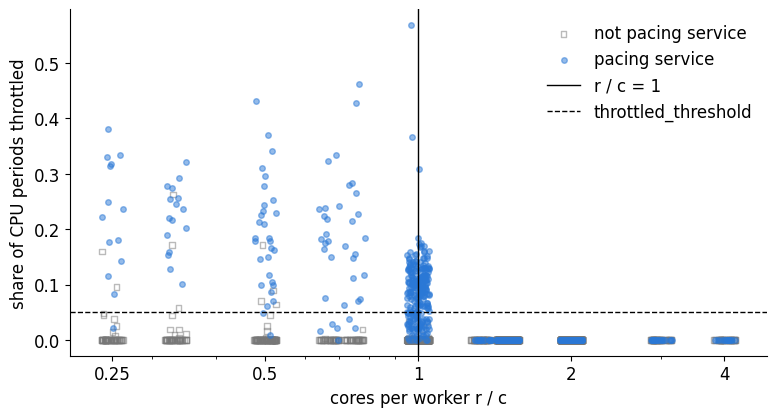

**What this shows** (share of runs with more than `throttled_threshold` of their CPU periods throttled):
- **pacing services:** r < c: 91%, r = c: 72%, r > c: 0%
- **not pacing services:** r < c: 4%, r = c: 0%, r > c: 0%

The largest throttled share of any run is 0.0% with r > c, 57% with r = c and 46% with r < c.

In [2]:
# Source: run_states (throttled_fraction and the knobs of dataset.csv); the sideways jitter is for display only
rng = np.random.default_rng(0)
fig, ax = plt.subplots(figsize=(9, 4.5))
for role in ("not pacing", "pacing"):
    chosen = states[states["role"] == role]
    x = chosen["cores_per_worker"] * np.exp(rng.uniform(-0.05, 0.05, len(chosen)))
    filled = role == "pacing"
    ax.scatter(x, chosen["throttled"], s=16, alpha=0.5, marker="o" if filled else "s", linewidths=1,
               facecolors="#2a78d6" if filled else "none", edgecolors="#2a78d6" if filled else "#777777", label=f"{role} service")
ax.axvline(1, color="black", linewidth=1, label="r / c = 1")
ax.axhline(throttled_threshold, color="black", linewidth=1, linestyle="--", label="throttled_threshold")
ax.set(xscale="log", xlabel="cores per worker r / c", ylabel="share of CPU periods throttled")
ax.set_xticks([0.25, 0.5, 1, 2, 4], ["0.25", "0.5", "1", "2", "4"])
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper right")
plt.show()

throttled = states.assign(is_throttled=states["throttled"] > throttled_threshold)
share = throttled.pivot_table(index="role", columns="provisioning", values="is_throttled", aggfunc="mean").reindex(index=roles, columns=list(PROVISIONING))
largest = states.groupby("provisioning")["throttled"].max()
display(Markdown(
    "**What this shows** (share of runs with more than `throttled_threshold` of their CPU periods throttled):\n"
    + "\n".join(f"- **{role} services:** " + ", ".join(f"{cls}: {share.loc[role, cls]:.0%}" for cls in PROVISIONING if not np.isnan(share.loc[role, cls]))
                for role in roles)
    + f"\n\nThe largest throttled share of any run is {largest['r > c']:.1%} with r > c, {largest['r = c']:.0%} with r = c "
      f"and {largest['r < c']:.0%} with r < c."))

Throttling hits almost only the pacing services, which are busy for about half of the time (a few runs of the other
services with $r < c$ are throttled as well), and only runs with at most one core per worker. One core per worker is
not enough although a worker computes on one thread: the service also spends
CPU time outside its workers (receiving items, handing them over, reporting metrics), and with $r = c$ that time has
to come out of the same quota. This explanation is plausible but not tested here.

### 3. Across Loads, Within a Run: The Probe Against the Run

**Measure.** For every run and service, the ratio

$$q = m_\text{run} / m_\text{probe},$$

where $m_\text{run}$ is the mean execution time of the items of the run (ms, `processing_mean_ms`) and $m_\text{probe}$
the mean execution time of the same service at the same configuration in the probe just before the run (ms). Both
are measured at one configuration; only the load differs: the probe rate (printed in Section 1) against the rate
$\lambda$ of the run, which is several times higher. For the pacing service, the run is at a utilization of about 0.5
per worker by construction. If the execution time does not depend on the load, $q$ scatters around 1.

**Caveats.**
- The probe lasts a few seconds, so $m_\text{probe}$ is the mean of few items and a single $q$ is noisy; the median
  over many runs is not.
- The probe is the first thing a service does in a run. If a service is slower right after its container started
  (warm-up), $m_\text{probe}$ is too large and $q$ too small. Such a bias would hide a slowdown under load, not create
  one.

**Summary statistic.** Per group of runs: the median of $q$ with a 95% bootstrap interval (resampling runs), and a
Wilcoxon signed-rank test of whether $\ln q$ is centered at 0. Assumptions of the test: the runs are independent of
each other (each run has its own probe and its own random configuration), and $\ln q$ is symmetric around its median.
With hundreds of runs, the test detects even an effect of a fraction of a percent; whether an effect matters is decided
by the size of the median, not by the p-value.

**The figure below** has one panel for the pacing services and one for the others. In each panel, one box per
provisioning class: the distribution of $q$ over the runs (box: quartiles; line: median; whiskers: 5th to 95th
percentile), on a logarithmic vertical axis. The horizontal line marks $q = 1$. What to look at: how far each box lies
from the line, and whether that distance shrinks from $r < c$ to $r > c$.

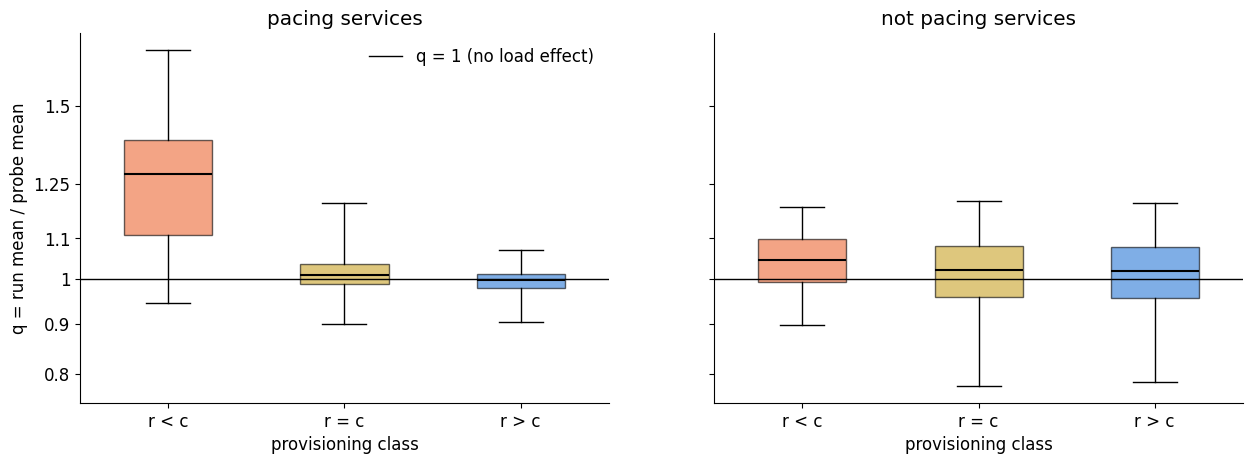

,role,provisioning,median,low,high,p,runs,rate / probe rate
0,not pacing,r < c,1.0446,1.0342,1.0557,0.0000,233,14.1705
1,not pacing,r = c,1.0203,1.0130,1.0303,0.0006,444,8.4110
2,not pacing,r > c,1.0188,1.0138,1.0249,0.0000,823,8.3605
3,pacing,r < c,1.2779,1.1660,1.3158,0.0000,96,12.2863
4,pacing,r = c,1.0084,1.0051,1.0134,0.0000,238,9.1584
5,pacing,r > c,0.9976,0.9950,0.9998,0.0194,416,8.4372


In [3]:
# Source: run_states (processing_mean_ms of dataset.csv, probed_processing_ms of run.json)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
for ax, role in zip(axes, roles):
    chosen = states[states["role"] == role]
    data = [chosen.loc[chosen["provisioning"] == cls, "probe_ratio"] for cls in PROVISIONING]
    boxes = ax.boxplot(data, whis=(5, 95), showfliers=False, patch_artist=True, widths=0.5, tick_labels=list(PROVISIONING))
    for patch, cls in zip(boxes["boxes"], PROVISIONING):
        patch.set(facecolor=class_styles[cls][0], alpha=0.6)
    for median in boxes["medians"]:
        median.set(color="black", linewidth=1.5)
    ax.axhline(1, color="black", linewidth=1, label="q = 1 (no load effect)")
    ax.set(yscale="log", title=f"{role} services", xlabel="provisioning class")
    ax.set_yticks([0.8, 0.9, 1, 1.1, 1.25, 1.5], ["0.8", "0.9", "1", "1.1", "1.25", "1.5"])
    ax.minorticks_off()
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("q = run mean / probe mean")
axes[0].legend(frameon=False, loc="upper right")
plt.show()

probe_summary = ratio_table(states, "probe_ratio", ["role", "provisioning"])
rate_ratio = (states["rate"] / states["probe_rate"]).groupby([states["role"], states["provisioning"]]).median()
probe_summary["rate / probe rate"] = [rate_ratio[row.role, row.provisioning] for row in probe_summary.itertuples()]
display(probe_summary.round(4))

In [4]:
def ratio_text(row) -> str:
    return f"{row['median']:.3f} [{row['low']:.3f}, {row['high']:.3f}], {int(row['runs'])} runs"

pacing_rows = probe_summary[probe_summary["role"] == "pacing"].set_index("provisioning")
other_rows = probe_summary[probe_summary["role"] == "not pacing"].set_index("provisioning")
per_service = ratio_table(states[states["pacing"]], "probe_ratio", ["service", "provisioning"])
per_service = per_service.pivot(index="service", columns="provisioning", values="median").rename(index=names).reindex(columns=list(PROVISIONING))
display(Markdown(
    "**What this shows** (median q with 95% interval):\n"
    + "- **Pacing services:** " + "; ".join(f"{cls}: {ratio_text(pacing_rows.loc[cls])}" for cls in PROVISIONING) + ".\n"
    + "- **Other services:** " + "; ".join(f"{cls}: {ratio_text(other_rows.loc[cls])}" for cls in PROVISIONING) + ".\n\n"
    + f"For the pacing services with r < c, a median item takes {pacing_rows.loc['r < c', 'median'] - 1:.0%} longer in the run than in the "
      f"probe, at a rate that is {rate_ratio['pacing', 'r < c']:.1f} times the probe rate (median). With r > c, the run and the probe "
      f"differ by {abs(pacing_rows.loc['r > c', 'median'] - 1):.1%} in the median run. The other services are slower in the run by "
      f"{other_rows.loc['r > c', 'median'] - 1:.1%} with r > c, at a rate {rate_ratio['not pacing', 'r > c']:.1f} times the probe rate.\n\n"
      "Median q of every pacing service:"))
display(per_service.round(3))

**What this shows** (median q with 95% interval):
- **Pacing services:** r < c: 1.278 [1.166, 1.316], 96 runs; r = c: 1.008 [1.005, 1.013], 238 runs; r > c: 0.998 [0.995, 1.000], 416 runs.
- **Other services:** r < c: 1.045 [1.034, 1.056], 233 runs; r = c: 1.020 [1.013, 1.030], 444 runs; r > c: 1.019 [1.014, 1.025], 823 runs.

For the pacing services with r < c, a median item takes 28% longer in the run than in the probe, at a rate that is 12.3 times the probe rate (median). With r > c, the run and the probe differ by 0.2% in the median run. The other services are slower in the run by 1.9% with r > c, at a rate 8.4 times the probe rate.

Median q of every pacing service:

provisioning,r < c,r = c,r > c
service,,,
audio-denoiser,1.330,1.034,1.007
cv-analyzer,1.155,1.007,1.000
ground-remover,NaN,0.995,0.985
image-transformer,NaN,NaN,0.984


The comparison separates three regimes. Under-provisioned pacing services ($r < c$) are clearly slower at the load of
the run than in the probe: this is the throttling of Section 2, which grows with the load. With one core per worker
the difference almost disappears, and with $r > c$ the run and the probe agree. The non-pacing services were never
throttled, yet they are slightly slower in the run in every class; Section 4 checks whether this small effect also
shows across runs.

### 4. Across Loads, Across Runs: The Same Configuration at Different Rates

**Measure.** Only the services that did not pace their chain (Section 1), and only configurations that occur in at
least two such runs whose rates differ by at least the factor `min_rate_ratio`. Within each configuration, the
logarithm of the run mean, $\ln m_\text{run}$, and the logarithm of the rate, $\ln \lambda$, are centered (their
average over the runs of the configuration is subtracted), so that only differences between runs of the same
configuration remain. The slope $e$ of a line through the origin, fitted by least squares to the centered values, is
the *elasticity* of the execution time with respect to the rate: by how many percent the mean execution time changes
per percent of rate. Doubling the rate multiplies the mean by $2^e$, so $e = 0$ is independence and $e = 0.1$ means
about 7% slower at twice the rate.

The 95% interval is a cluster bootstrap over the configurations: all runs of one configuration are resampled
together, because they share whatever no knob describes. Assumption: different configurations are independent.

These services were almost never throttled (Section 2), so this comparison hardly tests throttling. It tests whether
anything else makes a service slower at a higher rate, e.g. contention with the other services on the same host,
whose load rises with $\lambda$ as well.

**The figure below** has one panel per provisioning class. Horizontal axis: the centered $\ln \lambda$; vertical axis:
the centered $\ln m_\text{run}$; one point per run. The black line has the fitted slope $e$. What to look at: whether
the point cloud tilts upward.

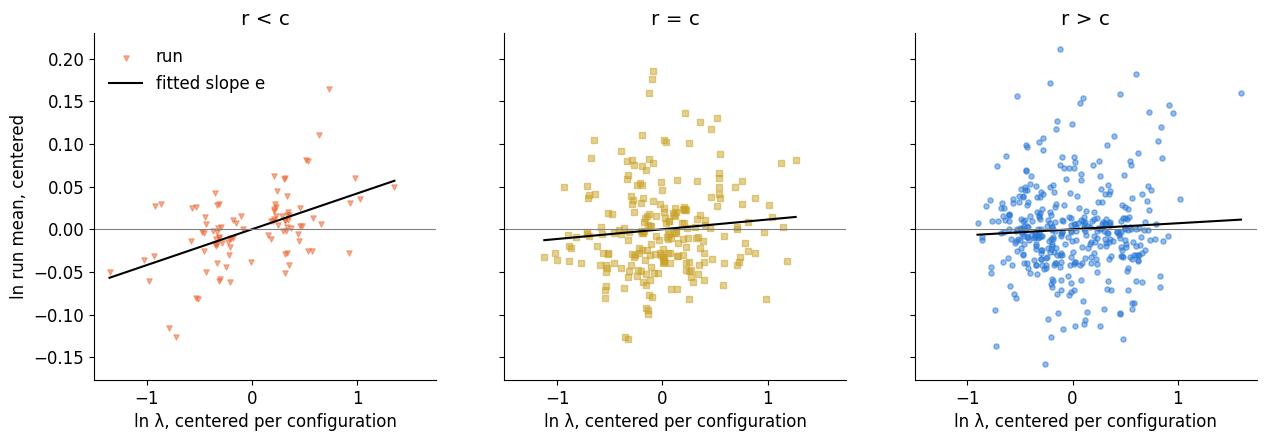

**What this shows** (elasticity e with 95% interval; in brackets the rough elasticity implied by the probe comparison of Section 3 for the non-pacing services, ln(median q) / ln(median rate ratio)):
- **r < c:** e = 0.042 [0.019, 0.069], 46 configurations, 98 runs; doubling the rate: ×1.030 (implied by Section 3: e ≈ 0.016)
- **r = c:** e = 0.011 [-0.005, 0.028], 56 configurations, 228 runs; doubling the rate: ×1.008 (implied by Section 3: e ≈ 0.009)
- **r > c:** e = 0.007 [-0.010, 0.023], 103 configurations, 393 runs; doubling the rate: ×1.005 (implied by Section 3: e ≈ 0.009)

In [5]:
# Source: run_states, non-pacing services only
min_rate_ratio = 1.2   # a configuration qualifies only if its runs differ in rate by at least this factor
repeated = repeated_configurations(states, min_rate_ratio)
elasticity = {cls: within_configuration_elasticity(repeated[repeated["provisioning"] == cls]) for cls in PROVISIONING}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)
for ax, cls in zip(axes, PROVISIONING):
    part = repeated[repeated["provisioning"] == cls]
    color, marker = class_styles[cls]
    ax.scatter(part["log_rate"], part["log_mean"], s=14, alpha=0.5, color=color, marker=marker, label="run")
    span = np.array([part["log_rate"].min(), part["log_rate"].max()])
    ax.plot(span, elasticity[cls]["e"] * span, color="black", linewidth=1.5, label="fitted slope e")
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.set(title=cls, xlabel="ln λ, centered per configuration")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("ln run mean, centered")
axes[0].legend(frameon=False, loc="upper left")
plt.show()

# rough elasticity implied by Section 3 for the same services: ln(median q) / ln(median rate ratio)
implied = {cls: np.log(other_rows.loc[cls, "median"]) / np.log(rate_ratio["not pacing", cls]) for cls in PROVISIONING}
display(Markdown(
    "**What this shows** (elasticity e with 95% interval; in brackets the rough elasticity implied by the probe comparison of Section 3 for the "
    "non-pacing services, ln(median q) / ln(median rate ratio)):\n"
    + "\n".join(f"- **{cls}:** e = {elasticity[cls]['e']:.3f} [{elasticity[cls]['low']:.3f}, {elasticity[cls]['high']:.3f}], "
                f"{elasticity[cls]['configurations']} configurations, {elasticity[cls]['runs']} runs; doubling the rate: "
                f"×{2 ** elasticity[cls]['e']:.3f} (implied by Section 3: e ≈ {implied[cls]:.3f})" for cls in PROVISIONING)))

With $r = c$ and $r > c$, the elasticity across runs and the rough elasticity implied by the probe comparison are of
the same small size, and the interval of $e$ contains 0: a higher rate makes these services at most slightly slower.
The probe comparison detects the effect although the elasticity is small because its rates differ much more than the
rates of the runs of one configuration here. With $r < c$, the elasticity across runs is clearly positive and larger
than the rough estimate from the probe. These services are rarely throttled (Section 2), so something else that grows
with the load and that more cores per worker relieve slows them down, e.g. workers that compete for too few cores
without exhausting the quota.

### 5. Within Runs: The State of the Service When an Item Starts

Within one run, the configuration and the rate are fixed. What still varies from item to item is the state of the
service when the item starts. Three states, each compared within a run as a ratio of median execution times (the
median is not moved by the few very slow items of a run):

- **Next to other items** (runs with $c > 1$ only; `next_ratio`): the items that started while at least one other item
  of the service was being processed, against those that started alone. A ratio above 1 means workers slow each other
  down, e.g. by sharing the quota, the memory bandwidth or the caches of the host. The share of items that start next
  to another grows with the utilization, so this effect becomes a load effect.
- **Momentary load** (`window_ratio`): the third of the items with the most arrivals at the service in the second
  before they started (`window_s` of `run_states`), against the third with the fewest. This is the within-run version
  of Sections 3 and 4, and the state in which throttling should show up: many recent arrivals use up the quota.
- **Gap before the item** (`gap_ratio`, items that started alone only): the third with the longest time since the
  service last finished an item, against the third with the shortest, which started right after the previous item,
  mostly from the queue. A ratio above 1 is warm-up: the service is slower after a pause.

Each ratio is summarized over the runs of a group as in Section 3: the median with a 95% bootstrap interval, and a
Wilcoxon test of whether the log ratio is centered at 0, under the same assumptions.

**The figure below** has one panel per state. Vertical axis: the groups of runs, by role (pacing or not) and
provisioning class; horizontal axis: the ratio of median execution times. A point is the median over the runs of a
group (filled: pacing services, hollow: the others), its bar the 95% interval; the vertical line marks a ratio of 1
(no effect). The horizontal axes differ between the panels. What to look at: which points lie
clearly right of the line, and whether they move toward it from $r < c$ to $r > c$.

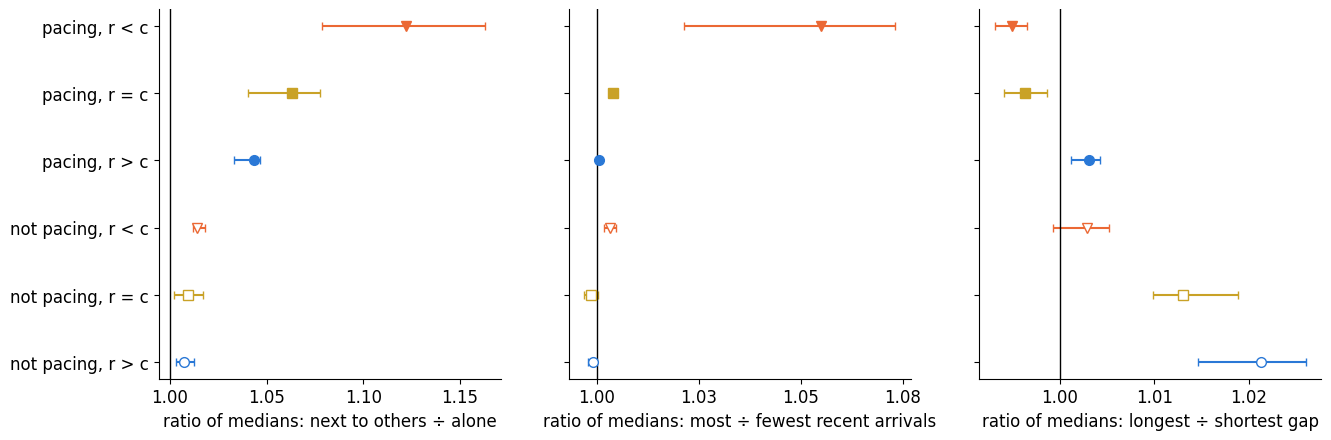

In [6]:
# Source: run_states (within-run statistics from records.csv)
measures = {"next_ratio": "next to others ÷ alone", "window_ratio": "most ÷ fewest recent arrivals", "gap_ratio": "longest ÷ shortest gap"}
within = {column: ratio_table(states, column, ["role", "provisioning"]) for column in measures}
groups = [(role, cls) for role in roles for cls in PROVISIONING]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True)
for ax, (column, label) in zip(axes, measures.items()):
    table = within[column].set_index(["role", "provisioning"])
    for y, (role, cls) in enumerate(groups):
        if (role, cls) not in table.index or np.isnan(table.loc[(role, cls), "median"]):
            continue
        row = table.loc[(role, cls)]
        color, marker = class_styles[cls]
        ax.errorbar(row["median"], y, xerr=[[row["median"] - row["low"]], [row["high"] - row["median"]]], fmt=marker, color=color,
                    markersize=7, capsize=3, markerfacecolor=color if role == "pacing" else "white")
    ax.axvline(1, color="black", linewidth=1)
    ax.set(xlabel=f"ratio of medians: {label}")
    ax.xaxis.set_major_locator(plt.MaxNLocator(4))
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_yticks(range(len(groups)), [f"{role}, {cls}" for role, cls in groups])
axes[0].invert_yaxis()
for ax in axes:
    ax.xaxis.set_major_formatter(plt.FormatStrFormatter("%.2f"))
plt.show()

In [7]:
def within_text(column: str, role: str, cls: str) -> str:
    table = within[column].set_index(["role", "provisioning"])
    if (role, cls) not in table.index or np.isnan(table.loc[(role, cls), "median"]):
        return "no runs"
    return ratio_text(table.loc[(role, cls)]) + f", p = {table.loc[(role, cls), 'p']:.2g}"

next_all = ratio_table(states, "next_ratio", ["provisioning"]).set_index("provisioning")
next_pacing = within["next_ratio"].set_index(["role", "provisioning"]).loc["pacing"]
display(Markdown(
    "**What this shows** (median ratio with 95% interval, number of runs, Wilcoxon p):\n"
    + "\n".join(f"- **{label}:**\n" + "\n".join(f"  - {role}: " + "; ".join(f"{cls}: {within_text(column, role, cls)}" for cls in PROVISIONING) for role in roles)
                for column, label in measures.items())
    + "\n\nNext to other items, over all runs with several workers: "
    + "; ".join(f"{cls}: {ratio_text(next_all.loc[cls])}" for cls in PROVISIONING)
    + f". For the pacing services, which are busy for about half of the time, an item that starts next to another takes "
      f"{next_pacing.loc['r < c', 'median'] - 1:.1%} longer in the median run with r < c and still {next_pacing.loc['r > c', 'median'] - 1:.1%} "
      "longer with r > c: over-provisioning shrinks the effect but does not remove it."))

**What this shows** (median ratio with 95% interval, number of runs, Wilcoxon p):
- **next to others ÷ alone:**
  - pacing: r < c: 1.122 [1.079, 1.163], 96 runs, p = 2.2e-17; r = c: 1.063 [1.041, 1.078], 60 runs, p = 2.2e-11; r > c: 1.043 [1.033, 1.046], 64 runs, p = 9.9e-12
  - not pacing: r < c: 1.014 [1.012, 1.018], 153 runs, p = 3.1e-19; r = c: 1.009 [1.002, 1.017], 63 runs, p = 0.0003; r > c: 1.007 [1.003, 1.013], 75 runs, p = 5.9e-05
- **most ÷ fewest recent arrivals:**
  - pacing: r < c: 1.055 [1.021, 1.073], 96 runs, p = 5e-17; r = c: 1.004 [1.003, 1.005], 238 runs, p = 5.7e-13; r > c: 1.000 [1.000, 1.001], 416 runs, p = 0.32
  - not pacing: r < c: 1.003 [1.002, 1.005], 233 runs, p = 1.4e-07; r = c: 0.999 [0.997, 1.000], 444 runs, p = 0.013; r > c: 0.999 [0.998, 1.000], 823 runs, p = 0.00032
- **longest ÷ shortest gap:**
  - pacing: r < c: 0.996 [0.994, 0.997], 96 runs, p = 2.6e-05; r = c: 0.997 [0.995, 0.999], 238 runs, p = 0.045; r > c: 1.002 [1.001, 1.003], 416 runs, p = 6.2e-06
  - not pacing: r < c: 1.002 [0.999, 1.004], 233 runs, p = 0.1; r = c: 1.010 [1.008, 1.015], 444 runs, p = 2.3e-21; r > c: 1.017 [1.012, 1.021], 823 runs, p = 2.2e-53

Next to other items, over all runs with several workers: r < c: 1.029 [1.023, 1.035], 249 runs; r = c: 1.029 [1.017, 1.041], 123 runs; r > c: 1.021 [1.014, 1.032], 139 runs. For the pacing services, which are busy for about half of the time, an item that starts next to another takes 12.2% longer in the median run with r < c and still 4.3% longer with r > c: over-provisioning shrinks the effect but does not remove it.

Two of the three states depend on provisioning, one does not:
- **Momentary load** follows the throttling of Section 2: the under-provisioned pacing services are slower right after
  many arrivals, and with $r > c$ the effect is gone.
- **Next to other items** shrinks with more cores per worker but remains with $r > c$, most clearly for the busy
  pacing services. Workers of one service slow each other down by a few percent even when each has more than a core of
  quota; whatever they share besides the quota (memory bandwidth, caches, the host's cores), the quota does not
  reserve it.
- **Gap before the item** shows at most a small effect in every class, the largest for the non-pacing services with
  $r > c$, which pause the most: a slight warm-up after a pause. The warm-up effect that `explain_6` found in the first
  campaign, whose services released their items once per second, is small in this campaign. Throttled pacing
  services ($r < c$, $r = c$) show the opposite: they are slightly faster after a pause than right after the previous
  item. A likely reason, not tested here: during a pause the quota of the container is not used up, so the first item
  after it is less likely to be throttled.

### 6. Answer: Does Over-Provisioning Ensure Assumption 3?

The rendered summary below collects the numbers of Sections 2 to 5 for the over-provisioned runs ($r > c$) next to the
under-provisioned ones.

In [8]:
cp, cu = "r > c", "r < c"
gap_other = within["gap_ratio"].set_index(["role", "provisioning"]).loc["not pacing"]
display(Markdown(
    "| Check | r < c | r > c |\n|---|---|---|\n"
    f"| Pacing services throttled (Section 2) | {share.loc['pacing', cu]:.0%} of runs | {share.loc['pacing', cp]:.0%} of runs |\n"
    f"| Pacing services, run ÷ probe (Section 3) | {pacing_rows.loc[cu, 'median']:.3f} | {pacing_rows.loc[cp, 'median']:.3f} |\n"
    f"| Other services, run ÷ probe (Section 3) | {other_rows.loc[cu, 'median']:.3f} | {other_rows.loc[cp, 'median']:.3f} |\n"
    f"| Other services, elasticity e (Section 4) | {elasticity[cu]['e']:.3f} [{elasticity[cu]['low']:.3f}, {elasticity[cu]['high']:.3f}] "
    f"| {elasticity[cp]['e']:.3f} [{elasticity[cp]['low']:.3f}, {elasticity[cp]['high']:.3f}] |\n"
    f"| Pacing services, most ÷ fewest recent arrivals (Section 5) | {within['window_ratio'].set_index(['role', 'provisioning']).loc[('pacing', cu), 'median']:.3f} "
    f"| {within['window_ratio'].set_index(['role', 'provisioning']).loc[('pacing', cp), 'median']:.3f} |\n"
    f"| Pacing services with p > 1, next to others ÷ alone (Section 5) | {next_pacing.loc[cu, 'median']:.3f} | {next_pacing.loc[cp, 'median']:.3f} |\n"
    f"| Other services, longest ÷ shortest gap (Section 5) | {gap_other.loc[cu, 'median']:.3f} | {gap_other.loc[cp, 'median']:.3f} |"))

| Check | r < c | r > c |
|---|---|---|
| Pacing services throttled (Section 2) | 91% of runs | 0% of runs |
| Pacing services, run ÷ probe (Section 3) | 1.278 | 0.998 |
| Other services, run ÷ probe (Section 3) | 1.045 | 1.019 |
| Other services, elasticity e (Section 4) | 0.042 [0.019, 0.069] | 0.007 [-0.010, 0.023] |
| Pacing services, most ÷ fewest recent arrivals (Section 5) | 1.055 | 1.000 |
| Pacing services with p > 1, next to others ÷ alone (Section 5) | 1.122 | 1.043 |
| Other services, longest ÷ shortest gap (Section 5) | 1.002 | 1.017 |

**Over-provisioning ensures the large part of Assumption 3, not all of it.**

- **What $r > c$ removes:** throttling, and with it the load effect that matters most. Under-provisioned pacing
  services are clearly slower at the load of their run than at the probe rate and are slower right after many arrivals;
  with $r > c$ both differences disappear. One core per worker ($r = c$) is not enough to rule out throttling.
- **What remains with $r > c$:** effects of a few percent. Items that start while other workers of the same service are
  busy are slower, and services are slightly slower at higher rates even when they are not throttled (the elasticity
  is small). Neither is a matter of the quota, so no amount of cores per worker removes them. The weaker form of
  Assumption 3 from `explain_6` (execution times in deployment at most as long as in the benchmark) would then call for
  a benchmark in the slowest state. Here that state is not the same for every service: for a busy service with several
  workers it is all workers busy, for a service that often pauses it is right after a pause (Section 5).

**Why a few percent can still matter.** Pegasus computes the waiting time from the mean execution time, and the
waiting time reacts strongly to the mean when the utilization $\rho$ is high. The cell below takes the median slowdown
of an item next to others for the over-provisioned pacing services (Section 5) as a factor $k$ on the mean, i.e. the
case that every item of a busy service starts next to others, and computes the node bound of Pegasus
(`martingale_closed_form_node_bound`, Poisson arrivals) of a service with mean execution time `mean_s`, coefficient of
variation `cv` and violation probability `epsilon`, once with the mean $m$ and once with $k \cdot m$, at the same
arrival rate. The ratio of the two bounds is how much a bound computed from a benchmark with the smaller mean would
have to grow to stay valid.

In [9]:
mean_s, cv, epsilon = 0.1, 0.1, 0.05   # illustrative service: 100 ms mean execution time, 10% item-to-item scatter, 95th percentile
utilizations = np.array([0.3, 0.5, 0.7, 0.8, 0.9])   # utilization rho = rate x mean_s with the benchmark mean
k = next_pacing.loc["r > c", "median"]   # slowdown next to others, over-provisioned pacing services (Section 5)
bound = lambda mean, rate: martingale_closed_form_node_bound(mean, (cv * mean) ** 2, "poisson", rate, epsilon)[0]
growth = [bound(k * mean_s, rho / mean_s) / bound(mean_s, rho / mean_s) for rho in utilizations]
display(Markdown(f"With k = {k:.3f}, the bound must grow by a factor of "
                 + ", ".join(f"{g:.2f} at ρ = {rho:g}" for g, rho in zip(growth, utilizations)) + "."))

With k = 1.043, the bound must grow by a factor of 1.06 at ρ = 0.3, 1.09 at ρ = 0.5, 1.15 at ρ = 0.7, 1.25 at ρ = 0.8, 1.69 at ρ = 0.9.

At low utilization the remaining effect shifts the bound by about as much as it shifts the mean; near saturation it is
amplified many times, because waiting grows like $1 / (1 - \rho)$ (the queue empties more slowly). A margin on the
mean, or a benchmark in the slowest state, is therefore worth its price for services that run at high utilization.

**Limits.**
- **Utilization range.** The over-provisioned pacing services ran at a utilization close to the campaign's target
  (output below); nothing here shows how the remaining effects behave closer to saturation, where more items start next
  to others and where they matter most.
- **Own load or neighbors' load.** All three services of a chain share a host, and their loads rise together with
  $\lambda$. The slowdown of the non-pacing services may come from their own rate or from the work of the pacing service
  next to them; this campaign cannot separate the two. If it is the neighbors, it is a violation of Assumption 1
  (performance isolation) rather than of Assumption 3.
- **The probe.** It lasts a few seconds and runs first; its noise averages out over runs, a warm-up bias would make
  the probe comparison err toward hiding a load effect (Section 3).
- **One kind of arrivals.** All runs have Poisson arrivals; whether burstier arrivals change execution times beyond
  what the momentary load of Section 5 shows is not tested.

In [10]:
utilization = states[states["pacing"]].groupby("provisioning")["utilization"].quantile([0.05, 0.95]).unstack()
display(Markdown("Utilization of the pacing services (5th to 95th percentile over runs): "
                 + "; ".join(f"{cls}: {utilization.loc[cls, 0.05]:.2f} to {utilization.loc[cls, 0.95]:.2f}" for cls in PROVISIONING) + "."))

Utilization of the pacing services (5th to 95th percentile over runs): r < c: 0.44 to 0.89; r = c: 0.43 to 0.58; r > c: 0.43 to 0.55.